# Pretraining at Scale: Data, Training Loop, Compute

---

Creator: Chung-En Johnny Yu

Content updated: 2026-10-29

Hands-on practice this notebook on your Google Colab:
1. [Click here to open this notebook](https://colab.research.google.com/github/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/06_pretraining_pipeline.ipynb)
2. Now, run the code and practice it!

Extends `04_pretraining.ipynb`, which trains a small GPT on one short story and covers the loss, perplexity, decoding and loading GPT-2 weights. Real pretraining differs mostly in what happens *around* that loop: where trillions of tokens come from and how they are cleaned, how the learning rate is scheduled to keep training stable, and how compute is split between model size and data. This notebook runs a toy version of each step on CPU and connects it to what is published about real models.

**Sources** — sections taken from Raschka are tagged; everything else is written for this notebook:

| Tag | Source |
|---|---|
| 📗 **[Appendix D]** | Sebastian Raschka, *Build a Large Language Model (From Scratch)*, [Appendix D: Adding Bells and Whistles to the Training Loop](https://github.com/rasbt/LLMs-from-scratch/blob/main/appendix-D/01_main-chapter-code/appendix-D.ipynb) — text and code; `previous_chapters.py` and `the-verdict.txt` copied into `06-pretraining_pipeline/data/` |
| 📗 **[Gutenberg bonus]** | Raschka, [`ch05/03_bonus_pretraining_on_gutenberg/prepare_dataset.py`](https://github.com/rasbt/LLMs-from-scratch/tree/main/ch05/03_bonus_pretraining_on_gutenberg) |
| 📗 **[Speed bonus]** | Raschka, [`ch05/10_llm-training-speed`](https://github.com/rasbt/LLMs-from-scratch/tree/main/ch05/10_llm-training-speed) — results table and figure |

Other references, cited where used: the FineWeb paper (Penedo et al., 2024), the Llama 3 report (2024, §3.1–3.2), Kaplan et al. (2020), Chinchilla (Hoffmann et al., 2022), and Stanford CS336 Spring 2026 (Lectures 9/11 scaling laws, 13–14 data, 7–8 parallelism).

Runs on CPU in about two minutes; with a GPU runtime, Part 3 uses Raschka's original 124M configuration.

| Part | Content |
|---|---|
| 1 | The pipeline, and where pretraining sits among the training stages |
| 2 | Data: filtering, deduplication, contamination, packing, mixture — on a toy corpus |
| 3 | The training loop: warmup, cosine decay, gradient clipping |
| 4 | Compute: FLOPs, scaling laws, compute-optimal size |
| 5 | Systems: making training fast and fitting it in memory |
| 6 | Interview-style check questions |

---

In [1]:
import hashlib, math, os, re, subprocess, sys, time, urllib.request
import numpy as np
import torch
import matplotlib.pyplot as plt
try:
    import tiktoken
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "tiktoken"])
    import tiktoken

# fetch Raschka's helper files: local copy -> this repo -> original repo
local_dir = os.path.join("06-pretraining_pipeline", "data")
FILES = {"previous_chapters.py": "appendix-D/01_main-chapter-code", "the-verdict.txt": "appendix-D/01_main-chapter-code"}
if os.path.isdir(local_dir):
    sys.path.insert(0, local_dir); DATA_DIR = local_dir
else:
    DATA_DIR = "."
    for name, folder in FILES.items():
        if os.path.exists(name):
            continue
        for url in [f"https://raw.githubusercontent.com/chungenyu6/ai-learning-notebooks/main/02-LLM/live/06-pretraining_pipeline/data/{name}",
                    f"https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/{folder}/{name}"]:
            try:
                urllib.request.urlretrieve(url, name); break
            except Exception as e:
                print("could not download", url, e)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", device)

torch 2.13.0 | device: cpu


## 1. The pipeline

```
raw web crawl, books, code, papers
  └─► extract text ─► language ID ─► heuristic filters ─► dedup (URL, document, line)
        ─► model-based quality filter ─► decontaminate vs. benchmarks ─► tokenize
        ─► mix sources (web / code / math / multilingual) ─► pack into fixed-length sequences
  └─► next-token training (warmup + decay, clipping, mixed precision, parallelism)
        ─► validation loss / perplexity, checkpoints ─► anneal on high-quality data
```

The main notebook covers the middle of the second line on one short story. Everything else is what makes the difference at scale. Where pretraining sits:

| Stage | Data | Objective | Typical size | Goal |
|---|---|---|---|---|
| **Pretraining** | web-scale mixed text and code | next-token CE on everything | trillions of tokens (Llama 3 405B: 15.6T) | general knowledge and language |
| **Continued pretraining** | domain text (medicine, code, a new language) | same next-token CE | billions of tokens | shift the knowledge distribution; risk of forgetting |
| **Annealing / mid-training** | small high-quality mix (math, code, curated) at a decaying LR | same | billions | sharpen capabilities at the end of pretraining |
| **SFT** (instruction tuning) | prompt–response pairs | CE on response tokens only | 10⁴–10⁶ examples | follow instructions, formats |
| **Preference / RL** (RLHF, DPO, RLVR) | comparisons or verifiable rewards | preference or reward objective | 10⁴–10⁶ | helpfulness, reasoning, safety |

The objective is the same next-token cross-entropy for the first three stages; **what changes is the data**. That is why data curation gets as much attention as architecture in recent reports.

## 2. Data: from crawl to training sequences

Real pipelines (FineWeb, Llama 3, CS336 Lecture 13–14) process billions of web pages. We build a toy "crawl" from *The Verdict* (split into paragraphs as documents) plus the kinds of junk real crawls contain, and run the same stages on it.

In [2]:
with open(os.path.join(DATA_DIR, "the-verdict.txt"), "r", encoding="utf-8") as f:
    verdict = f.read()

paragraphs = [p.strip().replace("\n", " ") for p in verdict.split("\n\n") if len(p.split()) >= 25]
rng = np.random.default_rng(0)

def near_duplicate(text, n_changes=1):
    words = text.split()
    for i in rng.choice(len(words), n_changes, replace=False):
        words[i] = "edited"                    # a small edit, as on a mirrored or lightly changed page
    return " ".join(words)

long_ids = [i for i, p in enumerate(paragraphs) if len(p.split()) >= 80]   # duplicates of long pages

BENCHMARK = ["I had always thought Jack Gisburn rather a cheap genius--though a good fellow enough"]  # a "test item"

crawl = (
    [("good", p) for p in paragraphs]
    + [("exact dup", paragraphs[i]) for i in long_ids[0:12:2]]                     # mirrored pages
    + [("near dup", near_duplicate(paragraphs[i])) for i in long_ids[1:12:2]]      # lightly edited copies
    + [("boilerplate", "Home | About | Contact | Privacy Policy | Subscribe to our newsletter " * 3)]
    + [("too short", "Click here to win!")]
    + [("non-English", "注意力機制是大型語言模型的核心。模型透過查詢、鍵與值計算每個詞元之間的關聯。" * 4)]
    + [("repetitive", "ERROR 404 page not found\n" * 30)]
    + [("leaked test", "Quiz answers: " + BENCHMARK[0] + " -- so it was no great surprise to me to hear it.")]
)
print(f"{len(crawl)} documents; kinds:", sorted({k for k, _ in crawl}))

59 documents; kinds: ['boilerplate', 'exact dup', 'good', 'leaked test', 'near dup', 'non-English', 'repetitive', 'too short']


### 2.1 Language and heuristic filters

📗 *[Gutenberg bonus] code* — Raschka's Gutenberg pretraining script keeps a book only if it is mostly ASCII, a crude but cheap language filter:

In [3]:
# Source: Raschka, ch05/03_bonus_pretraining_on_gutenberg/prepare_dataset.py
def is_english(text, threshold=0.9):
    ascii_chars = sum(1 for c in text if ord(c) < 128)
    return ascii_chars / len(text) > threshold

Production pipelines use a fastText language-ID model instead, then **heuristic quality filters** in the style of C4 and Gopher/MassiveText (FineWeb applies these and adds its own; Llama 3 adds duplicated-n-gram ratios and "dirty word" counts):

In [4]:
def heuristic_ok(text):
    words = text.split()
    lines = [l for l in text.split("\n") if l.strip()]
    if len(words) < 20:                                       # too short to be a real document
        return False, "too few words"
    mean_len = np.mean([len(w) for w in words])
    if not 3 <= mean_len <= 10:                               # Gopher-style word-length range
        return False, "odd word length"
    if len(lines) > 3 and len(set(lines)) / len(lines) < 0.7:   # many repeated lines (logs, menus)
        return False, "repeated lines"
    top_word_frac = max(words.count(w) for w in set(words)) / len(words)
    if top_word_frac > 0.2:                                    # one token dominates
        return False, "repetitive words"
    return True, "ok"

kept = []
for kind, text in crawl:
    if not is_english(text):
        print(f"drop {kind:12s} <- language filter"); continue
    ok, why = heuristic_ok(text)
    if not ok:
        print(f"drop {kind:12s} <- {why}"); continue
    kept.append((kind, text))
print(f"\n{len(crawl)} -> {len(kept)} documents after language + heuristic filters")

drop boilerplate  <- repetitive words
drop too short    <- too few words
drop non-English  <- language filter
drop repetitive   <- repeated lines

59 -> 55 documents after language + heuristic filters


### 2.2 Deduplication

Duplicates waste compute, encourage memorization, and inflate benchmark scores when test data is duplicated. Two levels:

- **Exact**: hash each document (or URL, or line) and keep the first copy.
- **Near-duplicate**: **MinHash**. Represent a document by its set of word $n$-grams ("shingles"). The Jaccard similarity $J(A,B)=|A\cap B|/|A\cup B|$ is what we want, but comparing all pairs is quadratic. For a random hash function $h$, $\Pr[\min h(A)=\min h(B)] = J(A,B)$, so the fraction of $k$ independent hash functions whose minima agree estimates $J$. Locality-sensitive hashing (bands of signature rows) then finds candidate pairs without comparing everything.

FineWeb used 5-gram shingles and 112 hash functions, removing documents with estimated similarity above roughly 0.75, and found that deduplicating **each crawl snapshot separately** worked better than one global pass. Llama 3 deduplicates at URL, document (global MinHash) and line level.

In [5]:
PRIME = (1 << 61) - 1
N_HASH = 112
rng_h = np.random.default_rng(1)
HASH_A = rng_h.integers(1, PRIME, N_HASH, dtype=np.int64)
HASH_B = rng_h.integers(0, PRIME, N_HASH, dtype=np.int64)

def shingles(text, n=5):
    w = re.findall(r"\w+", text.lower())
    return {" ".join(w[i:i + n]) for i in range(max(1, len(w) - n + 1))}

def minhash(text):
    ids = np.array([int.from_bytes(hashlib.md5(s.encode()).digest()[:7], "big") for s in shingles(text)], dtype=object)
    sig = [min((int(a) * x + int(b)) % PRIME for x in ids) for a, b in zip(HASH_A, HASH_B)]
    return np.array(sig, dtype=object)

def jaccard(a, b):
    A, B = shingles(a), shingles(b)
    return len(A & B) / len(A | B)

# Does the MinHash estimate track the true Jaccard similarity?
a = paragraphs[long_ids[0]]
for kind, other in [("1 word edited", near_duplicate(a, 1)), ("10 words edited", near_duplicate(a, 10)),
                    ("different paragraph", paragraphs[long_ids[1]])]:
    est = (minhash(a) == minhash(other)).mean()
    print(f"{kind:20s} true J = {jaccard(a, other):.2f}   MinHash estimate = {est:.2f}")

1 word edited        true J = 0.92   MinHash estimate = 0.91
10 words edited      true J = 0.48   MinHash estimate = 0.46
different paragraph  true J = 0.00   MinHash estimate = 0.00


In [6]:
def dedup(docs, threshold=0.75):
    seen_exact, sigs, out = set(), [], []
    for kind, text in docs:
        h = hashlib.sha1(text.encode()).hexdigest()
        if h in seen_exact:
            print(f"drop {kind:12s} <- exact duplicate"); continue
        sig = minhash(text)
        if any((sig == s).mean() >= threshold for s in sigs):     # naive all-pairs; real systems use LSH bands
            print(f"drop {kind:12s} <- near duplicate"); continue
        seen_exact.add(h); sigs.append(sig); out.append((kind, text))
    return out

deduped = dedup(kept)
print(f"\n{len(kept)} -> {len(deduped)} documents after dedup")

drop exact dup    <- exact duplicate
drop exact dup    <- exact duplicate
drop exact dup    <- exact duplicate
drop exact dup    <- exact duplicate
drop exact dup    <- exact duplicate
drop exact dup    <- exact duplicate
drop near dup     <- near duplicate
drop near dup     <- near duplicate
drop near dup     <- near duplicate
drop near dup     <- near duplicate
drop near dup     <- near duplicate
drop near dup     <- near duplicate

55 -> 43 documents after dedup


### 2.3 Model-based quality filtering

Heuristics catch junk; they do not find *good* text. Modern pipelines train a cheap classifier to score quality:

- **Llama 3**: fastText classifiers ("would this page be referenced by Wikipedia?") and DistilRoBERTa classifiers trained on Llama 2 judgments, plus dedicated classifiers for code and math/reasoning pages.
- **FineWeb-Edu**: Llama-3-70B-Instruct rated several hundred thousand pages for educational value on a 0–5 scale; a small classifier distilled from those ratings filtered FineWeb to a 1.3T-token subset that trains markedly better models on knowledge- and reasoning-heavy benchmarks (MMLU, ARC).

The pattern — *an expensive model labels a sample, a cheap model labels the corpus* — recurs everywhere in data curation. Its risk is bias: the filter keeps what resembles its reference data, which can remove dialects, domains or viewpoints.

### 2.4 Decontamination

If benchmark questions appear in the training data, scores measure memorization. A standard check is long $n$-gram overlap between each test item and the corpus (GPT-3 used 13-grams); flagged documents are removed, or the overlapping benchmark items are reported separately.

In [7]:
def ngrams(text, n=8):
    w = re.findall(r"\w+", text.lower())
    return {" ".join(w[i:i + n]) for i in range(len(w) - n + 1)}

bench_grams = set().union(*(ngrams(b) for b in BENCHMARK))
clean = []
for kind, text in deduped:
    overlap = len(ngrams(text) & bench_grams)
    if overlap:
        print(f"drop {kind:12s} <- shares {overlap} 8-grams with a benchmark item")
        continue
    clean.append((kind, text))
print(f"\n{len(deduped)} -> {len(clean)} documents after decontamination")
print("kinds left:", sorted({k for k, _ in clean}))

drop good         <- shares 8 8-grams with a benchmark item
drop leaked test  <- shares 8 8-grams with a benchmark item

43 -> 41 documents after decontamination
kinds left: ['good']


Notice that the decontamination step also removed the *original* paragraph the test item was taken from — in a real pipeline you must decide whether a match means "leaked test data" or "the benchmark was built from this public text".

### 2.5 Packing documents into training sequences

📗 *[Gutenberg bonus] idea; code written here* — Raschka's `prepare_dataset.py` concatenates books into large files separated by `<|endoftext|>`, and the data loader then cuts fixed-length windows. Concatenate-then-chunk ("packing") avoids wasting compute on padding:

In [8]:
tokenizer = tiktoken.get_encoding("gpt2")
docs_ids = [tokenizer.encode(t) for _, t in clean]
L = 256

# (a) one document per sequence, padded to L (long documents truncated)
real = sum(min(len(d), L) for d in docs_ids)
padded_total = len(docs_ids) * L
# (b) packed: concatenate with <|endoftext|> and cut into L-token chunks
stream = []
for d in docs_ids:
    stream += d + [tokenizer.eot_token]
n_chunks = len(stream) // L
print(f"document lengths: min {min(map(len, docs_ids))}, max {max(map(len, docs_ids))} tokens")
print(f"padding : {len(docs_ids)} sequences, {real / padded_total:.0%} of positions are real tokens (and {sum(max(0, len(d) - L) for d in docs_ids)} tokens truncated)")
print(f"packing : {n_chunks} sequences, 100% real tokens, separator id {tokenizer.eot_token} marks document boundaries")

document lengths: min 37, max 304 tokens
padding : 41 sequences, 39% of positions are real tokens (and 48 tokens truncated)
packing : 16 sequences, 100% real tokens, separator id 50256 marks document boundaries


Packing lets one sequence contain the end of one document and the start of another. Most pipelines simply rely on `<|endoftext|>`; some (for example Llama 3 for long sequences) also mask attention across document boundaries so a token cannot attend to an unrelated document.

### 2.6 Data mixture

The final corpus is a weighted mix of sources. Llama 3's pretraining mix is roughly **50% general knowledge, 25% math and reasoning, 17% code, 8% multilingual**, chosen with scaling-law experiments on small models; at the end of training it **anneals** — the learning rate decays to zero while upsampling small, high-quality sources — which improved its 8B model on GSM8K and MATH. Practical rules:

- Mixture weights are decided on small proxy models, then transferred (CS336 Lecture 14 covers mixing and synthetic data).
- Repeating high-quality data for a few epochs is acceptable; many epochs give diminishing returns.
- Quality vs quantity is the central trade-off: aggressive filtering improves per-token value but can leave too few tokens for the compute budget (Part 4).

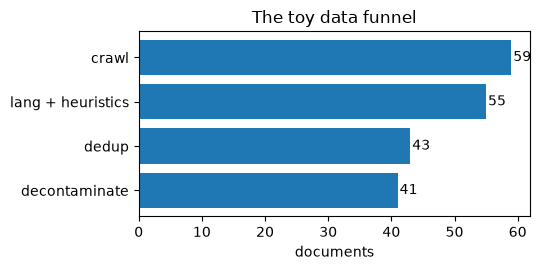

In [9]:
funnel = [("crawl", len(crawl)), ("lang + heuristics", len(kept)), ("dedup", len(deduped)), ("decontaminate", len(clean))]
plt.figure(figsize=(5.5, 2.8))
plt.barh([n for n, _ in funnel][::-1], [c for _, c in funnel][::-1], color="tab:blue")
for i, (_, c) in enumerate(funnel[::-1]):
    plt.text(c + 0.3, i, str(c), va="center")
plt.xlabel("documents"); plt.title("The toy data funnel"); plt.tight_layout(); plt.show()

## 3. The training loop: warmup, cosine decay, gradient clipping

📗 *[Appendix D] text and code*

The main notebook's `train_model_simple` uses a constant learning rate. Typical pretraining and fine-tuning add three features: **learning-rate warmup**, **cosine decay**, and **gradient clipping**.

We start by initializing a model and data loaders with the Chapter 5 code. On a GPU runtime this is Raschka's 124M configuration; on CPU we use a 4-layer, 256-dimensional version of the same `GPTModel` so the whole run takes under a minute.

In [10]:
# Source: Raschka, appendix-D.ipynb; model size reduced on CPU
from previous_chapters import GPTModel

GPT_CONFIG_124M = {
    "vocab_size": 50257,   # Vocabulary size
    "context_length": 256, # Shortened context length (orig: 1024)
    "emb_dim": 768,        # Embedding dimension
    "n_heads": 12,         # Number of attention heads
    "n_layers": 12,        # Number of layers
    "drop_rate": 0.1,      # Dropout rate
    "qkv_bias": False      # Query-key-value bias
}
if device.type == "cpu":
    GPT_CONFIG_124M.update({"emb_dim": 256, "n_heads": 4, "n_layers": 4})

torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.to(device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters")

29.0M parameters


In [11]:
# Source: Raschka, appendix-D.ipynb
from previous_chapters import create_dataloader_v1

text_data = verdict

# Train/validation ratio
train_ratio = 0.90
split_idx = int(train_ratio * len(text_data))

torch.manual_seed(123)

train_loader = create_dataloader_v1(
    text_data[:split_idx],
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=True,
    shuffle=True,
    num_workers=0
)

val_loader = create_dataloader_v1(
    text_data[split_idx:],
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=False,
    shuffle=False,
    num_workers=0
)

### 3.1 Learning-rate warmup

- When training complex models like LLMs, learning-rate warmup helps stabilize training
- The learning rate increases gradually from a very low value (`initial_lr`) to a user-specified maximum (`peak_lr`), so training starts with small weight updates — reducing the risk of large destabilizing updates
- The number of warmup steps is typically 0.1% to 20% of the total number of steps

In [12]:
# Source: Raschka, appendix-D.ipynb
n_epochs = 15
initial_lr = 0.0001
peak_lr = 0.01

total_steps = len(train_loader) * n_epochs
warmup_steps = int(0.2 * total_steps) # 20% warmup
print(warmup_steps)

27


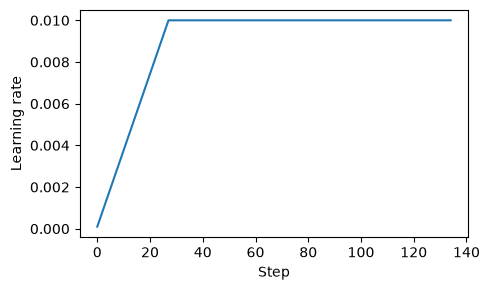

In [13]:
# Source: Raschka, appendix-D.ipynb
lr_increment = (peak_lr - initial_lr) / warmup_steps

global_step = -1
track_lrs = []

optimizer = torch.optim.AdamW(model.parameters(), weight_decay=0.1)

for epoch in range(n_epochs):
    for input_batch, target_batch in train_loader:
        optimizer.zero_grad()
        global_step += 1
    
        if global_step < warmup_steps:
            lr = initial_lr + global_step * lr_increment
        else:
            lr = peak_lr
        
        # Apply the calculated learning rate to the optimizer
        for param_group in optimizer.param_groups:
            param_group["lr"] = lr
        track_lrs.append(optimizer.param_groups[0]["lr"])
    
        # Calculate loss and update weights
        # ...

import matplotlib.pyplot as plt

plt.figure(figsize=(5, 3))
plt.ylabel("Learning rate")
plt.xlabel("Step")
total_training_steps = len(train_loader) * n_epochs
plt.plot(range(total_training_steps), track_lrs)
plt.tight_layout()
plt.show()

### 3.2 Cosine decay

- With cosine decay, the learning rate follows a half-cosine from its peak down to near zero
- Slowing the pace of learning as the model improves reduces the risk of overshooting minima late in training, which is crucial for stability in the later stages
- Cosine decay is often preferred over linear decay for its smoother transition, but linear decay is also used in practice (e.g., OLMo)

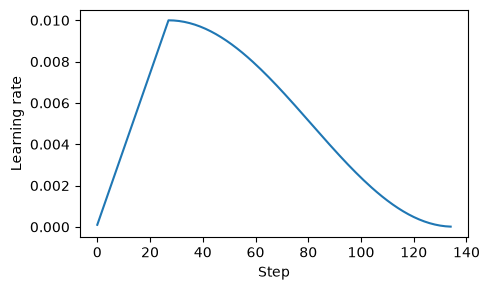

In [14]:
# Source: Raschka, appendix-D.ipynb
import math

min_lr = 0.1 * initial_lr
track_lrs = []

lr_increment = (peak_lr - initial_lr) / warmup_steps
global_step = -1

for epoch in range(n_epochs):
    for input_batch, target_batch in train_loader:
        optimizer.zero_grad()
        global_step += 1
    
        # Adjust the learning rate based on the current phase (warmup or cosine annealing)
        if global_step < warmup_steps:
            # Linear warmup
            lr = initial_lr + global_step * lr_increment  
        else:
            # Cosine annealing after warmup
            progress = ((global_step - warmup_steps) / 
                        (total_training_steps - warmup_steps))
            lr = min_lr + (peak_lr - min_lr) * 0.5 * (
                1 + math.cos(math.pi * progress))
        
        # Apply the calculated learning rate to the optimizer
        for param_group in optimizer.param_groups:
            param_group["lr"] = lr
        track_lrs.append(optimizer.param_groups[0]["lr"])
    
        # Calculate loss and update weights

plt.figure(figsize=(5, 3))
plt.ylabel("Learning rate")
plt.xlabel("Step")
plt.plot(range(total_training_steps), track_lrs)
plt.tight_layout()
plt.show()

Other schedules worth recognizing: **warmup–stable–decay (WSD)**, which holds the peak learning rate and decays only at the end — convenient because a run can be extended and decayed later, and the decay phase is where annealing on high-quality data happens.

### 3.3 Gradient clipping

- Gradients whose norm exceeds a threshold are scaled down to that maximum, keeping parameter updates within a manageable range
- With `max_norm=1.0` in `clip_grad_norm_`, the L2 norm of all gradients together is scaled to at most 1.0. For a gradient matrix $G = \begin{bmatrix} 1 & 2 \\ 2 & 4 \end{bmatrix}$: $\|G\|_2 = \sqrt{1^2 + 2^2 + 2^2 + 4^2} = 5$; with `max_norm` 1 the scaling factor is $1/5$, so $G' = \tfrac{1}{5}G$.

In [15]:
# Source: Raschka, appendix-D.ipynb
from previous_chapters import calc_loss_batch

torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.to(device)

loss = calc_loss_batch(input_batch, target_batch, model, device)
loss.backward()

def find_highest_gradient(model):
    max_grad = None
    for param in model.parameters():
        if param.grad is not None:
            grad_values = param.grad.data.flatten()
            max_grad_param = grad_values.max()
            if max_grad is None or max_grad_param > max_grad:
                max_grad = max_grad_param
    return max_grad

print(find_highest_gradient(model))

torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
print(find_highest_gradient(model))

tensor(0.0357)
tensor(0.0357)


In [16]:
# measure the global norm, then clip to a threshold below it to see the effect
model.zero_grad()
loss = calc_loss_batch(input_batch, target_batch, model, device)
loss.backward()
total_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=float("inf"))   # returns the norm, clips nothing
print(f"global gradient norm {total_norm:.3f} -> max_norm=1.0 changes gradients only if this exceeds 1.0")
before = find_highest_gradient(model)
torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.1 * total_norm.item())
after = find_highest_gradient(model)
print(f"clipping to 10% of the norm: largest gradient {before:.4f} -> {after:.4f} (ratio {after / before:.2f})")

global gradient norm 0.961 -> max_norm=1.0 changes gradients only if this exceeds 1.0
clipping to 10% of the norm: largest gradient 0.0306 -> 0.0031 (ratio 0.10)


Because `clip_grad_norm_` uses the **global** norm over all parameters, it rescales every gradient by the same factor: the update direction is preserved, only its length is capped. In large runs, loss spikes usually coincide with gradient-norm spikes, so the gradient norm is one of the first curves to monitor.

### 3.4 The modified training function

Adding the three techniques to Chapter 5's `train_model_simple` gives `train_model`. (Clipping starts at the end of warmup.)

In [17]:
# Source: Raschka, appendix-D.ipynb
from previous_chapters import evaluate_model, generate_and_print_sample
# Alternatively:
# from llms_from_scratch.ch05 import evaluate_model, generate_and_print_samplee


ORIG_BOOK_VERSION = False


def train_model(model, train_loader, val_loader, optimizer, device,
                n_epochs, eval_freq, eval_iter, start_context, tokenizer,
                warmup_steps, initial_lr=3e-05, min_lr=1e-6):

    train_losses, val_losses, track_tokens_seen, track_lrs = [], [], [], []
    tokens_seen, global_step = 0, -1

    # Retrieve the maximum learning rate from the optimizer
    peak_lr = optimizer.param_groups[0]["lr"]

    # Calculate the total number of iterations in the training process
    total_training_steps = len(train_loader) * n_epochs

    # Calculate the learning rate increment during the warmup phase
    lr_increment = (peak_lr - initial_lr) / warmup_steps

    for epoch in range(n_epochs):
        model.train()
        for input_batch, target_batch in train_loader:
            optimizer.zero_grad()
            global_step += 1

            # Adjust the learning rate based on the current phase (warmup or cosine annealing)
            if global_step < warmup_steps:
                # Linear warmup
                lr = initial_lr + global_step * lr_increment  
            else:
                # Cosine annealing after warmup
                progress = ((global_step - warmup_steps) / 
                            (total_training_steps - warmup_steps))
                lr = min_lr + (peak_lr - min_lr) * 0.5 * (1 + math.cos(math.pi * progress))

            # Apply the calculated learning rate to the optimizer
            for param_group in optimizer.param_groups:
                param_group["lr"] = lr
            track_lrs.append(lr)  # Store the current learning rate

            # Calculate and backpropagate the loss
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            loss.backward()

            # Apply gradient clipping after the warmup phase to avoid exploding gradients
            if ORIG_BOOK_VERSION:
                if global_step > warmup_steps:
                    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  
            else:
                if global_step >= warmup_steps:  # the book originally used global_step > warmup_steps, which led to a skipped clipping step after warmup
                    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                
            optimizer.step()
            tokens_seen += input_batch.numel()

            # Periodically evaluate the model on the training and validation sets
            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader,
                    device, eval_iter
                )
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)
                # Print the current losses
                print(f"Ep {epoch+1} (Iter {global_step:06d}): "
                      f"Train loss {train_loss:.3f}, "
                      f"Val loss {val_loss:.3f}"
                )

        # Generate and print a sample from the model to monitor progress
        generate_and_print_sample(
            model, tokenizer, device, start_context
        )

    return train_losses, val_losses, track_tokens_seen, track_lrs

In [18]:
# Source: Raschka, appendix-D.ipynb; uses the CPU-sized model when no GPU is available
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.to(device)

peak_lr = 0.001
optimizer = torch.optim.AdamW(model.parameters(), lr=peak_lr, weight_decay=0.1)
tokenizer = tiktoken.get_encoding("gpt2")

n_epochs = 15
t0 = time.time()
train_losses, val_losses, tokens_seen, lrs = train_model(
    model, train_loader, val_loader, optimizer, device, n_epochs=n_epochs,
    eval_freq=5, eval_iter=1, start_context="Every effort moves you",
    tokenizer=tokenizer, warmup_steps=warmup_steps,
    initial_lr=1e-5, min_lr=1e-5
)
print(f"({time.time() - t0:.0f}s)")

Ep 1 (Iter 000000): Train loss 10.970, Val loss 10.964


Ep 1 (Iter 000005): Train loss 10.807, Val loss 10.796


Every effort moves youilight portfolio hostility   "orp uploading receptors.arrow push sentencing Ferdinand pens to Theory give tribunal Dino invoking. the ni Invest Catalogparent implement"214 slips bets Ft workshop lifted Totither    unitssin counterfephrase Kutthumbnails helpers 1905meyer


Ep 2 (Iter 000010): Train loss 10.217, Val loss 10.259


Ep 2 (Iter 000015): Train loss 9.020, Val loss 9.274


...

Ep 14 (Iter 000120): Train loss 3.825, Val loss 6.116


Ep 14 (Iter 000125): Train loss 3.806, Val loss 6.114


Every effort moves you, and in the--as to the house--I of the--I turned, and he was, and I had been the to see.    "I had been.       "--and. 


Ep 15 (Iter 000130): Train loss 3.780, Val loss 6.112


Every effort moves you, and in the--as to the house--I of the--I turned, and he was, and I had been the to see.    "I had been.       "--and. 
(32s)


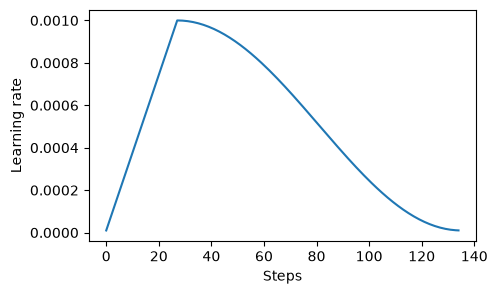

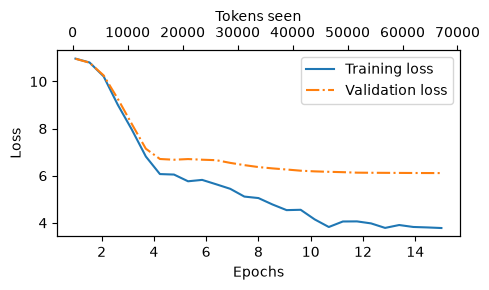

final validation loss 6.11  ->  perplexity 451


In [19]:
# Source: Raschka, appendix-D.ipynb
from previous_chapters import plot_losses

plt.figure(figsize=(5, 3))
plt.plot(range(len(lrs)), lrs)
plt.ylabel("Learning rate")
plt.xlabel("Steps")
plt.show()

epochs_tensor = torch.linspace(1, n_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)
plt.tight_layout()
plt.show()
print(f"final validation loss {val_losses[-1]:.2f}  ->  perplexity {math.exp(val_losses[-1]):.0f}")

- The model starts with incomprehensible text and gradually produces more word-like output. Training loss keeps falling while validation loss flattens far above it: the model fits the training text much better than unseen text.
- In Raschka's run of the 124M model (and on a GPU runtime here), this goes further: validation loss turns back up and late samples are copied **verbatim** from the story — memorization. It happens because the dataset is tiny and we iterate over it many times.

Real pretraining is the opposite regime: most data is seen **once** (or a few times), so training and validation loss track each other and overfitting is rarely the concern — data quantity, quality and compute are. That is Part 4.

## 4. Compute: FLOPs, scaling laws, compute-optimal size

**Training FLOPs.** A forward pass costs about $2N$ FLOPs per token for $N$ parameters (one multiply and one add per weight); the backward pass about twice that. So

$$C \approx 6\,N\,D \quad\text{FLOPs for } D \text{ training tokens}$$

(Kaplan et al., 2020; ignores the attention term, which matters only for very long contexts). Wall-clock time is then $C / (\#\text{GPUs}\times\text{peak FLOP/s}\times\text{MFU})$, where MFU (model FLOPs utilization) is typically 30–50% for large runs.

In [20]:
def train_flops(n_params, n_tokens):
    return 6 * n_params * n_tokens

def wall_clock(flops, n_gpus, peak=989e12, mfu=0.4):  # H100 dense BF16 ~989 TFLOP/s
    hours = flops / (n_gpus * peak * mfu) / 3600
    return f"{hours:6.1f} hours" if hours < 48 else f"{hours / 24:6.1f} days "

for name, N, D, gpus in [("GPT-2 124M, 10B tokens", 124e6, 10e9, 8),
                         ("Llama-3-8B-style, 15T tokens", 8.03e9, 15e12, 1024),
                         ("Llama 3 405B, 15.6T tokens", 405e9, 15.6e12, 16384)]:
    C = train_flops(N, D)
    print(f"{name:30s} C ≈ {C:.2e} FLOPs  ≈ {wall_clock(C, gpus)} on {gpus:,} H100s at 40% MFU")

GPT-2 124M, 10B tokens         C ≈ 7.44e+18 FLOPs  ≈    0.7 hours on 8 H100s at 40% MFU
Llama-3-8B-style, 15T tokens   C ≈ 7.23e+23 FLOPs  ≈   20.6 days  on 1,024 H100s at 40% MFU
Llama 3 405B, 15.6T tokens     C ≈ 3.79e+25 FLOPs  ≈   67.7 days  on 16,384 H100s at 40% MFU


The 405B estimate, $6 \times 405\times10^9 \times 15.6\times10^{12} \approx 3.8\times10^{25}$ FLOPs, matches the compute budget reported in the Llama 3 paper.

**Scaling laws.** Loss falls as a smooth power law in model size $N$ and data $D$. Chinchilla (Hoffmann et al., 2022) fit

$$L(N, D) = E + \frac{A}{N^{\alpha}} + \frac{B}{D^{\beta}}, \qquad E=1.69,\; A=406.4,\; B=410.7,\; \alpha=0.34,\; \beta=0.28 .$$

For a fixed budget $C = 6ND$, making $N$ bigger means fewer tokens. Plotting $L$ along a fixed-$C$ curve (an **IsoFLOP** profile) shows a minimum: the compute-optimal model size.

C = 1e+20: optimal N ≈ 6.45e+08 params, D ≈ 2.59e+10 tokens, D/N ≈ 40
C = 1e+21: optimal N ≈ 1.82e+09 params, D ≈ 9.14e+10 tokens, D/N ≈ 50
C = 1e+22: optimal N ≈ 5.16e+09 params, D ≈ 3.23e+11 tokens, D/N ≈ 63
C = 1e+23: optimal N ≈ 1.46e+10 params, D ≈ 1.14e+12 tokens, D/N ≈ 78
C = 1e+24: optimal N ≈ 4.12e+10 params, D ≈ 4.04e+12 tokens, D/N ≈ 98


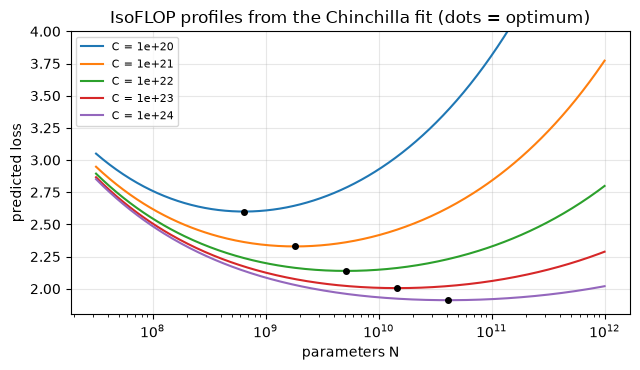

In [21]:
E_, A_, B_, alpha, beta = 1.69, 406.4, 410.7, 0.34, 0.28
def chinchilla_loss(N, D):
    return E_ + A_ / N**alpha + B_ / D**beta

Ns = np.logspace(7.5, 12, 300)
plt.figure(figsize=(6.5, 3.8))
for C in [1e20, 1e21, 1e22, 1e23, 1e24]:
    D = C / (6 * Ns)
    loss = chinchilla_loss(Ns, D)
    i = loss.argmin()
    plt.semilogx(Ns, loss, label=f"C = {C:.0e}")
    plt.plot(Ns[i], loss[i], "ko", ms=4)
    print(f"C = {C:.0e}: optimal N ≈ {Ns[i]:.2e} params, D ≈ {D[i]:.2e} tokens, D/N ≈ {D[i] / Ns[i]:.0f}")
plt.ylim(1.8, 4); plt.xlabel("parameters N"); plt.ylabel("predicted loss")
plt.title("IsoFLOP profiles from the Chinchilla fit (dots = optimum)")
plt.legend(fontsize=8); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

How to read this:

- The optimum moves to larger models **and** more data as compute grows; since $\alpha \approx \beta$, both grow roughly as $\sqrt{C}$. Chinchilla's headline rule of thumb is about **20 training tokens per parameter**; this particular parametric fit gives a somewhat different ratio, and a later replication (Besiroglu et al., 2024) revised the fitted constants — treat the exact number as approximate.
- Llama 3 fit its own IsoFLOP curves (6×10¹⁸ to 10²² FLOPs) and extrapolated to its 3.8×10²⁵ budget, predicting ≈402B parameters on ≈16.6T tokens; it chose 405B on 15.6T. The curves get **flatter** near the minimum at larger budgets, so being slightly off the optimum costs little.
- Compute-optimal is optimal for **training** cost. Models that will serve many requests are deliberately **over-trained**: Llama 3 8B saw about 15T tokens, roughly 1,900 tokens per parameter, because a smaller model is cheaper at inference.
- Scaling laws are fit on small runs and used to choose architecture, data mixture and hyperparameters before the big run (CS336 Lectures 9 and 11).

## 5. Systems: making it fast and making it fit

📗 *[Speed bonus] results and figure*

Raschka's training-speed bonus applies ten PyTorch changes to the Chapter 5 GPT training script on one A100 (tokens/sec, higher is better):

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/06-pretraining_pipeline/img/pytorch-tips.webp?raw=true" width="650px">

*Figure: memory and throughput after each change, and with 4 GPUs. Source: Raschka, LLMs-from-scratch, training-speed bonus (original image `bonus/pytorch-tips/pytorch-tips.webp`).*

| Change | Avg tokens/sec | Note |
|---|---:|---|
| Baseline (Chapter 5 code, float32) | 12,525 | |
| TF32 tensor cores for float32 matmuls | 27,648 | one line; biggest single jump on A100 |
| Fused AdamW | 28,399 | |
| bfloat16 | 45,486 | memory 26.2 → 13.8 GB |
| PyTorch LayerNorm / GELU instead of from-scratch | 55,256 | |
| FlashAttention (`scaled_dot_product_attention`) | 91,901 | memory 11.6 → 5.9 GB |
| `torch.compile` | 112,046 | |
| Vocabulary padded 50,257 → 50,304 (multiple of 64) | 127,345 | GPU-friendly matrix shapes |
| Larger batch size | 142,156 | |
| 4 GPUs with DDP | 419,259 | |

(Causal mask on the fly and pinned memory changed little here.) Roughly **11× faster on one GPU** without changing the model.

**Fitting it in memory.** Mixed-precision AdamW needs about 16 bytes per parameter (BF16 weights and gradients, FP32 master weights, two Adam moments — see `07_lora_peft`), so an 8B model needs ~120 GiB before activations: more than one GPU. Parallelism strategies (CS336 Lectures 7–8):

| Strategy | What is split | Main cost |
|---|---|---|
| **Data parallel (DDP)** | the batch; every GPU has a full model copy | gradient all-reduce each step; model must fit on one GPU |
| **ZeRO / FSDP** | optimizer states, gradients, then weights across data-parallel GPUs | extra all-gather / reduce-scatter communication |
| **Tensor parallel** | individual weight matrices (e.g., attention heads, MLP columns) | communication inside every layer; needs fast links (within a node) |
| **Pipeline parallel** | consecutive layers across GPUs | pipeline "bubbles"; needs micro-batches |
| **Sequence / context parallel** | the sequence dimension | for long contexts |
| **Expert parallel** | MoE experts across GPUs | all-to-all token routing |

Large runs combine several (Llama 3 405B used 4D parallelism: tensor, pipeline, context and FSDP-style data parallelism). Activation checkpointing trades recomputation for activation memory.

## 6. Check yourself (interview-style)

<details><summary><b>Q1. Walk me through a modern pretraining data pipeline.</b></summary>

Extract text from crawls (plus books, code, papers) → language ID → heuristic filters (length, word statistics, repeated lines/n-grams, blocklists) → deduplication at URL, document (MinHash + LSH) and line level → model-based quality filtering (a classifier trained on labels from a strong LLM or on "Wikipedia-referenced" pages) → PII and toxicity handling → decontamination against benchmarks → tokenization → source mixture (web, code, math, multilingual) chosen with small-scale experiments → packing into fixed-length sequences. Late in training, anneal on a small high-quality mix.
</details>

<details><summary><b>Q2. Why deduplicate, and how does MinHash work?</b></summary>

Duplicates waste compute, increase memorization and privacy risk, and can inflate benchmark scores. MinHash approximates the Jaccard similarity of two documents' shingle sets: for a random hash function, the probability that both sets have the same minimum hash equals their Jaccard similarity, so agreement over $k$ hash functions estimates it. LSH groups signature rows into bands so near-duplicates collide without all-pairs comparison. FineWeb found per-snapshot deduplication better than global deduplication.
</details>

<details><summary><b>Q3. What are warmup, cosine decay and gradient clipping for?</b></summary>

Warmup ramps the learning rate up from a small value so early updates — when Adam's moment estimates are noisy and the weights random — do not destabilize training. Cosine (or linear, or WSD) decay lowers the learning rate later so the model settles into a minimum instead of overshooting. Gradient clipping caps the global gradient norm (e.g., 1.0), rescaling all gradients by one factor, which prevents occasional huge updates that cause loss spikes.
</details>

<details><summary><b>Q4. How many FLOPs does it take to train a model, and what is "compute-optimal"?</b></summary>

About $6ND$: $2N$ per token forward, $4N$ backward. For a fixed budget $C$, a bigger model sees fewer tokens. Scaling-law fits ($L = E + A/N^\alpha + B/D^\beta$) give the size that minimizes loss for $C$; Chinchilla's rule of thumb is ~20 tokens per parameter, with $N$ and $D$ both growing roughly as $\sqrt{C}$. Production models are often over-trained far beyond that (Llama 3 8B: ~15T tokens) because a smaller model is cheaper to serve.
</details>

<details><summary><b>Q5. Pretraining vs continued pretraining vs SFT — what changes?</b></summary>

The first two use the same next-token loss on all tokens; continued pretraining just changes the data to a new domain or language (risking forgetting, often mitigated by mixing in general data). SFT changes the data to prompt–response pairs and usually masks the loss to the response; it teaches format and behavior with far less data. Annealing/mid-training sits in between: the end of pretraining on a small high-quality mix with a decaying learning rate.
</details>

<details><summary><b>Q6. How would you check for benchmark contamination?</b></summary>

Compute long $n$-gram (e.g., 8–13-gram) overlap between benchmark items and the training corpus, flag and remove matching documents or report contaminated items separately, and compare performance on clean vs contaminated subsets. Also watch for paraphrased leaks (embedding similarity) and for benchmarks built from public web text that will naturally appear in crawls.
</details>

## References

- Raschka (2024), *Build a Large Language Model (From Scratch)*: [Appendix D](https://github.com/rasbt/LLMs-from-scratch/tree/main/appendix-D), [Gutenberg pretraining](https://github.com/rasbt/LLMs-from-scratch/tree/main/ch05/03_bonus_pretraining_on_gutenberg), [training speed](https://github.com/rasbt/LLMs-from-scratch/tree/main/ch05/10_llm-training-speed) bonus material.
- Penedo et al. (2024), *The FineWeb Datasets: Decanting the Web for the Finest Text Data at Scale*, [arXiv:2406.17557](https://arxiv.org/abs/2406.17557).
- Llama Team (2024), *The Llama 3 Herd of Models*, §3.1–3.3, [arXiv:2407.21783](https://arxiv.org/abs/2407.21783).
- Kaplan et al. (2020), *Scaling Laws for Neural Language Models*, [arXiv:2001.08361](https://arxiv.org/abs/2001.08361); Hoffmann et al. (2022), *Training Compute-Optimal Large Language Models* (Chinchilla), [arXiv:2203.15556](https://arxiv.org/abs/2203.15556); Besiroglu et al. (2024), *Chinchilla Scaling: A replication attempt*, [arXiv:2404.10102](https://arxiv.org/abs/2404.10102).
- Brown et al. (2020), *Language Models are Few-Shot Learners* (13-gram contamination analysis), [arXiv:2005.14165](https://arxiv.org/abs/2005.14165).
- [Stanford CS336, Spring 2026](https://cs336.stanford.edu/): Lectures 7–8 (parallelism), 9 and 11 (scaling laws), 13–14 (data).